# Chapter 3 Practice: Market Direction (clean dataset), answer key

**Dataset:** `Smarket` from *An Introduction to Statistical Learning* (ISLP). It covers S&P 500 daily percentage returns for 2001–2005 (1,250 trading days). Each row holds the previous 5 days' returns (`Lag1`…`Lag5`), the previous day's volume in billions of shares (`Volume`), today's return (`Today`), and whether today was `Up` or `Down` (`Direction`).

**Why this dataset is "clean":** there are no missing values, the features are already built, and the label is already binary. That makes it the closest market-data match to MNIST's "is this a 5?" problem.

**How this notebook maps to `03_classification.ipynb`:**

| Book section | MNIST in the book | Smarket here |
|---|---|---|
| MNIST | `fetch_openml('mnist_784')` | `pd.read_csv(url)` |
| Training a Binary Classifier | `y_train_5` (is it a 5?) | `y_train_up` (is today Up?) |
| Measuring Accuracy / Dummy | 90% accuracy by always saying "not 5" | ~51% by always saying "Up" |
| Confusion Matrix, Precision/Recall | `cross_val_predict` | same |
| Precision/Recall Trade-off, ROC | `decision_function`, `roc_auc_score` | same |
| Multiclass | 10 digits | 3 classes: Down / Flat / Up |
| Error Analysis | normalized confusion matrix | same |
| Multilabel | [large digit, odd digit] | [Up, Big move] |
| Multioutput | denoising images | no natural analog, skipped |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", size=12)
plt.rc("axes", labelsize=12, titlesize=13)

## 1. Get the data
*(Book: "MNIST")*

In [2]:
url = "https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Smarket.csv"
smarket = pd.read_csv(url)
smarket.head()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.1913,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.2965,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.4112,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.2760,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.2057,0.213,Up


In [3]:
smarket.info()

<class 'pandas.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Year       1250 non-null   int64  
 1   Lag1       1250 non-null   float64
 2   Lag2       1250 non-null   float64
 3   Lag3       1250 non-null   float64
 4   Lag4       1250 non-null   float64
 5   Lag5       1250 non-null   float64
 6   Volume     1250 non-null   float64
 7   Today      1250 non-null   float64
 8   Direction  1250 non-null   str    
dtypes: float64(7), int64(1), str(1)
memory usage: 88.0 KB


In [4]:
smarket.describe()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
count,1250.000000,1250.000000,1250.000000,1250.000000,1250.000000,1250.00000,1250.000000,1250.000000
mean,2003.016000,0.003834,0.003919,0.001716,0.001636,0.00561,1.478305,0.003138
std,1.409018,1.136299,1.136280,1.138703,1.138774,1.14755,0.360357,1.136334
min,2001.000000,-4.922000,-4.922000,-4.922000,-4.922000,-4.92200,0.356070,-4.922000
25%,2002.000000,-0.639500,-0.639500,-0.640000,-0.640000,-0.64000,1.257400,-0.639500
50%,2003.000000,0.039000,0.039000,0.038500,0.038500,0.03850,1.422950,0.038500
75%,2004.000000,0.596750,0.596750,0.596750,0.596750,0.59700,1.641675,0.596750
max,2005.000000,5.733000,5.733000,5.733000,5.733000,5.73300,3.152470,5.733000


In [5]:
smarket["Direction"].value_counts()

Direction
Up      648
Down    602
Name: count, dtype: int64

### ⚠️ The trap in this dataset: `Today`

`Direction` is just the sign of `Today`. If `Today` stays in the features, the model scores 100%, and the result means nothing. This is **target leakage**. Ask of every column: *would I know this value before I make the prediction?*

- `Lag1`…`Lag5`, `Volume`: known before today's close ✅ (Volume is the previous day's volume in ISLP)
- `Today`: that's the answer ❌
- `Year`: used only to split the data, not as a feature

In [6]:
# Proof that Today leaks the label: the sign of Today reproduces Direction
# (the few mismatches are days where Today is exactly 0.000)
(smarket["Today"] > 0).eq(smarket["Direction"] == "Up").mean()

np.float64(0.9992)

## 2. Train/test split
*(Book: `X_train, X_test = X[:60000], X[60000:]`)*

The book splits MNIST by position because the dataset is already shuffled. Here the rows are in **time order**, and splitting by position is also the right choice for that reason: train on the past, test on the future. Following ISLP, 2001–2004 is the training set and 2005 is the test set.

In [7]:
feature_cols = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]

train_mask = smarket["Year"] < 2005
X_train = smarket.loc[train_mask, feature_cols]
X_test = smarket.loc[~train_mask, feature_cols]
len(X_train), len(X_test)

(998, 252)

## 3. Training a binary classifier
*(Book: `y_train_5 = (y_train == '5')`, `SGDClassifier`)*

In [8]:
y_train_up = (smarket.loc[train_mask, "Direction"] == "Up").to_numpy()
y_test_up = (smarket.loc[~train_mask, "Direction"] == "Up").to_numpy()
y_train_up.mean(), y_test_up.mean()

(np.float64(0.5080160320641283), np.float64(0.5595238095238095))

In [9]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_up)

some_day = X_train.iloc[[0]]
sgd_clf.predict(some_day), y_train_up[0]

(array([False]), np.True_)

## 4. Measuring accuracy using cross-validation
*(Book: `cross_val_score(..., cv=3, scoring="accuracy")` and `DummyClassifier`)*

Note: with `cv=3` on a classifier, scikit-learn uses `StratifiedKFold(shuffle=False)`. The folds are roughly contiguous blocks in time, so they don't mix past and future much. The messy notebook shows the strict version, `TimeSeriesSplit`.

In [10]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, X_train, y_train_up, cv=3, scoring="accuracy")

array([0.51351351, 0.50750751, 0.47289157])

In [11]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()  # always predicts the most frequent class ("Up")
cross_val_score(dummy_clf, X_train, y_train_up, cv=3, scoring="accuracy")

array([0.50750751, 0.50750751, 0.50903614])

**Lesson (same as the book's "never 5" classifier):** accuracy on its own means nothing. Here the SGD classifier does no better than a model that always says "Up". In MNIST the dummy scored 90% because the classes were imbalanced. Here the classes are almost balanced, so the dummy scores ~51%, and the bar any real model has to clear is that ~51%, not 0%.

## 5. Confusion matrix
*(Book: `cross_val_predict` + `confusion_matrix`)*

In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_up, cv=3)
cm = confusion_matrix(y_train_up, y_train_pred)
cm  # rows = actual [Down, Up], columns = predicted [Down, Up]

array([[277, 214],
       [287, 220]])

## 6. Precision and recall

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

print(f"precision: {precision_score(y_train_up, y_train_pred):.3f}")
print(f"recall:    {recall_score(y_train_up, y_train_pred):.3f}")
print(f"F1:        {f1_score(y_train_up, y_train_pred):.3f}")
print(f"base rate of Up days: {y_train_up.mean():.3f}")

precision: 0.507
recall:    0.434
F1:        0.468
base rate of Up days: 0.508


**How to read it:** for "predict Up", *precision* is the fraction of the model's "Up" calls that were really Up days. Compare it with the **base rate**: if precision ≈ base rate, the "Up" calls are no better than random picks.

## 7. Precision/recall trade-off
*(Book: `decision_function`, `precision_recall_curve`, threshold for 90% precision)*

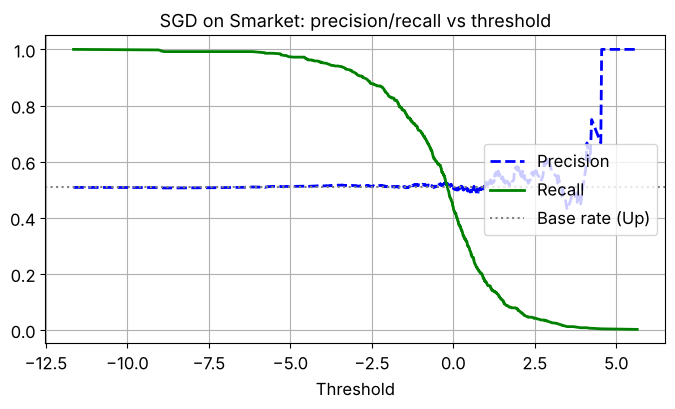

In [14]:
from sklearn.metrics import precision_recall_curve

y_scores = cross_val_predict(sgd_clf, X_train, y_train_up, cv=3,
                             method="decision_function")
precisions, recalls, thresholds = precision_recall_curve(y_train_up, y_scores)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.axhline(y_train_up.mean(), color="gray", linestyle=":", label="Base rate (Up)")
plt.xlabel("Threshold")
plt.grid()
plt.legend(loc="center right")
plt.title("SGD on Smarket: precision/recall vs threshold")
plt.show()

In [15]:
# Book: threshold for 90% precision. 90% is unreachable here, so aim for 55%
target_precision = 0.55
reachable = precisions[:-1] >= target_precision
if reachable.any():
    idx = reachable.argmax()
    threshold_target = thresholds[idx]
    y_pred_target = y_scores >= threshold_target
    print(f"threshold={threshold_target:.3f}  "
          f"precision={precision_score(y_train_up, y_pred_target):.3f}  "
          f"recall={recall_score(y_train_up, y_pred_target):.3f}  "
          f"(predicts Up on {y_pred_target.mean():.1%} of days)")
else:
    print("No threshold reaches the target precision")

threshold=1.258  precision=0.551  recall=0.138  (predicts Up on 12.7% of days)


**Lesson:** with MNIST, raising the threshold buys real precision. Here precision barely rises above the base rate and wobbles as the threshold goes up. When precision only climbs once a handful of predictions are left, that is noise, not signal.

## 8. The ROC curve, SGD vs Random Forest

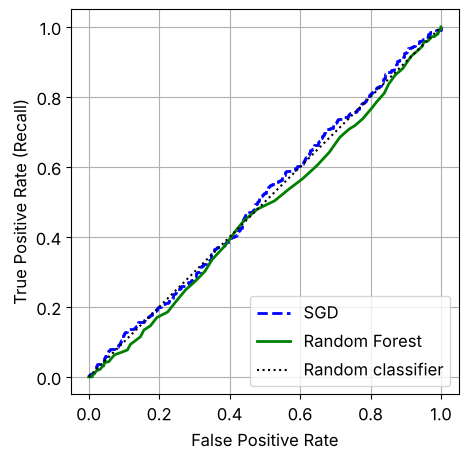

ROC AUC  SGD: 0.509
ROC AUC  RF:  0.478


In [16]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_up, cv=3,
                                    method="predict_proba")
y_scores_forest = y_probas_forest[:, 1]

fpr, tpr, _ = roc_curve(y_train_up, y_scores)
fpr_f, tpr_f, _ = roc_curve(y_train_up, y_scores_forest)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, "b--", linewidth=2, label="SGD")
plt.plot(fpr_f, tpr_f, "g-", linewidth=2, label="Random Forest")
plt.plot([0, 1], [0, 1], "k:", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.grid()
plt.legend(loc="lower right")
plt.show()

print(f"ROC AUC  SGD: {roc_auc_score(y_train_up, y_scores):.3f}")
print(f"ROC AUC  RF:  {roc_auc_score(y_train_up, y_scores_forest):.3f}")

**Lesson:** both curves hug the diagonal (AUC ≈ 0.5). The past 5 days' returns and volume carry almost no information about tomorrow's *direction*. That is the result you should expect: if direction were this easy to predict, traders would already have taken the profit out of it.

## 9. Multiclass classification: Down / Flat / Up
*(Book: SVC on 10 digits, `decision_function`, `OneVsRestClassifier`, SGD + `StandardScaler`)*

Three classes come from cutting `Today` at the **training-set** terciles. The cut points are computed on the training data only, so no information from the test set leaks in.

In [17]:
q1, q2 = smarket.loc[train_mask, "Today"].quantile([1/3, 2/3])
bins = [-np.inf, q1, q2, np.inf]
labels = ["Down", "Flat", "Up"]
y3 = pd.cut(smarket["Today"], bins=bins, labels=labels).astype(str).to_numpy()
y_train_3 = y3[train_mask.to_numpy()]
y_test_3 = y3[~train_mask.to_numpy()]
print(f"cut points: {q1:.3f}%, {q2:.3f}%")
pd.Series(y_train_3).value_counts()

cut points: -0.405%, 0.412%


Up      333
Down    333
Flat    332
Name: count, dtype: int64

In [18]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_clf = make_pipeline(StandardScaler(), SVC(random_state=42))
svm_clf.fit(X_train, y_train_3)
print(svm_clf.predict(some_day))
print(svm_clf.decision_function(some_day).round(2))  # one score per class (OvO votes aggregated)
print(svm_clf.classes_)

['Up']
[[ 1.   -0.23  2.23]]
['Down' 'Flat' 'Up']


In [19]:
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = make_pipeline(StandardScaler(), OneVsRestClassifier(SVC(random_state=42)))
ovr_clf.fit(X_train, y_train_3)
print(len(ovr_clf[-1].estimators_), "binary classifiers trained")

3 binary classifiers trained


In [20]:
sgd3 = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))
for name, model in [("dummy", DummyClassifier()), ("SGD", sgd3), ("SVC", svm_clf)]:
    scores = cross_val_score(model, X_train, y_train_3, cv=3, scoring="accuracy")
    print(f"{name:6s} {scores.round(3)}  mean={scores.mean():.3f}")

dummy  [0.333 0.333 0.334]  mean=0.334
SGD    [0.354 0.345 0.355]  mean=0.352


SVC    [0.354 0.405 0.346]  mean=0.369


## 10. Error analysis
*(Book: `ConfusionMatrixDisplay.from_predictions` with `normalize="true"` and the "errors only" view)*

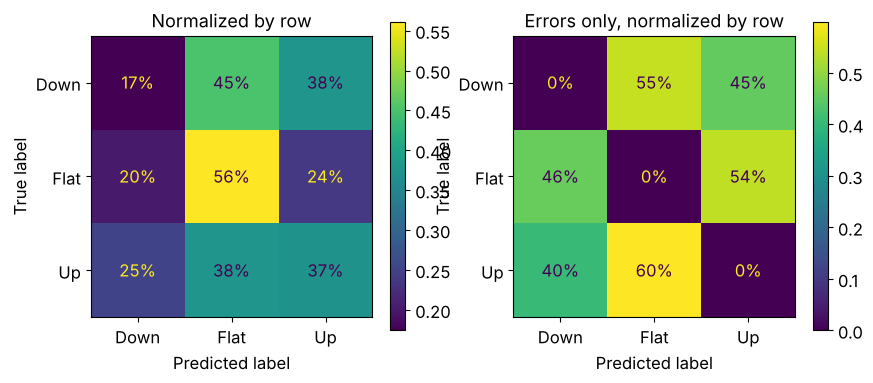

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred3 = cross_val_predict(svm_clf, X_train, y_train_3, cv=3)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_train_3, y_train_pred3, ax=axs[0],
                                        normalize="true", values_format=".0%",
                                        labels=labels)
axs[0].set_title("Normalized by row")
sample_weight = (y_train_pred3 != y_train_3)
ConfusionMatrixDisplay.from_predictions(y_train_3, y_train_pred3, ax=axs[1],
                                        sample_weight=sample_weight,
                                        normalize="true", values_format=".0%",
                                        labels=labels)
axs[1].set_title("Errors only, normalized by row")
plt.show()

**What to look for:** in MNIST the errors bunched into specific pairs, such as 5 being mistaken for 8. Here, see whether the model mostly predicts one class or whether Down and Up get confused with each other. A model that is close to random spreads its errors fairly evenly.

## 11. Multilabel classification: [Up, Big move]
*(Book: `y_multilabel = np.c_[y_train_large, y_train_odd]` + `KNeighborsClassifier`, `ClassifierChain`)*

There are two labels for each day:
- `Up`: is the return positive? (direction)
- `BigMove`: is |return| > 1%? (size of the move, which is a volatility question)

In [22]:
from sklearn.neighbors import KNeighborsClassifier

big_move = (smarket["Today"].abs() > 1.0).to_numpy()
y_train_big = big_move[train_mask.to_numpy()]
y_test_big = big_move[~train_mask.to_numpy()]
y_multilabel = np.c_[y_train_up, y_train_big]

knn_clf = make_pipeline(StandardScaler(), KNeighborsClassifier())
knn_clf.fit(X_train, y_multilabel)
knn_clf.predict(some_day)

array([[ True, False]])

In [23]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)
print("macro F1:", round(f1_score(y_multilabel, y_train_knn_pred, average="macro"), 3))
print("F1 per label [Up, BigMove]:",
      f1_score(y_multilabel, y_train_knn_pred, average=None).round(3))
print("BigMove base rate:", round(y_train_big.mean(), 3))

macro F1: 0.393
F1 per label [Up, BigMove]: [0.494 0.291]
BigMove base rate: 0.35


F1 depends on the base rate, so compare the two labels with ROC AUC instead, which doesn't:

In [24]:
for name, y_lbl in [("Up", y_train_up), ("BigMove", y_train_big)]:
    p = cross_val_predict(RandomForestClassifier(random_state=42), X_train, y_lbl,
                          cv=3, method="predict_proba")[:, 1]
    print(f"RF ROC AUC {name:8s}: {roc_auc_score(y_lbl, p):.3f}")

RF ROC AUC Up      : 0.478


RF ROC AUC BigMove : 0.634


In [25]:
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(make_pipeline(StandardScaler(), SVC()), cv=3, random_state=42)
chain_clf.fit(X_train, y_multilabel)
chain_clf.predict(some_day)

array([[1., 0.]])

**The key lesson of this notebook:** the same features that can't predict *direction* (AUC ≈ 0.5) do carry information about the *size* of the move (AUC clearly > 0.5). Large absolute returns follow large absolute returns, which is called **volatility clustering**. Quants rarely try to predict raw direction. They predict volatility, risk, or direction conditioned on other information.

## 12. Multioutput classification
The book's example removes noise from images, where every pixel is a separate multiclass output. There's no natural equivalent for this tabular dataset, so this section is skipped.

## 13. Final evaluation on the 2005 test set
*(Book exercise 1: refit on the full training set, evaluate on the test set **once**)*

In [26]:
final_models = {
    "dummy (always Up)": DummyClassifier(),
    "SGD": SGDClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}
for name, model in final_models.items():
    model.fit(X_train, y_train_up)
    acc = (model.predict(X_test) == y_test_up).mean()
    print(f"{name:18s} test accuracy = {acc:.3f}")

se = np.sqrt(0.5 * 0.5 / len(y_test_up))
print(f"\nStandard error of accuracy for a coin flip on {len(y_test_up)} days: ±{se:.3f}")
print(f"So anything inside ~{0.5 - 2*se:.3f}–{0.5 + 2*se:.3f} cannot be told apart from luck.")

dummy (always Up)  test accuracy = 0.560


SGD                test accuracy = 0.440


Random Forest      test accuracy = 0.532

Standard error of accuracy for a coin flip on 252 days: ±0.031
So anything inside ~0.437–0.563 cannot be told apart from luck.


In [27]:
rf_big = RandomForestClassifier(random_state=42).fit(X_train, y_train_big)
print(f"Test ROC AUC, BigMove (RF): {roc_auc_score(y_test_big, rf_big.predict_proba(X_test)[:, 1]):.3f}")
rf_up = final_models["Random Forest"]
print(f"Test ROC AUC, Up (RF):      {roc_auc_score(y_test_up, rf_up.predict_proba(X_test)[:, 1]):.3f}")

Test ROC AUC, BigMove (RF): 0.568
Test ROC AUC, Up (RF):      0.503


**Read these numbers carefully:**
- 2005 was an up year (56% Up days), so the dummy "always Up" model **wins** on the test set. This is **base-rate drift**: the share of Up days in the test period differs from training, and a model with no skill that leans "Up" looks good when the market rises.
- SGD below 50% and RF slightly above 50% both fall inside the ±2 SE band. Neither one shows skill.
- BigMove AUC is lower on the test set than in CV. 2005 was a calm year with fewer big moves, which is a reminder that market regimes change.

## 14. Takeaways and what a "good enough" answer looks like

| Check | Good-enough range |
|---|---|
| `Today` excluded from features | required |
| Split by time (2001–04 train / 2005 test), no shuffling across years | required |
| Dummy baseline computed and compared against | required |
| Binary accuracy (CV) | ~0.47–0.54, about the same as the dummy |
| Binary ROC AUC (CV) | ~0.45–0.55 |
| 3-class accuracy | ~0.33–0.38 vs a dummy at ~0.33 |
| BigMove ROC AUC | clearly above Up's AUC in CV (≈0.6+); lower on 2005 test (≈0.55–0.6) |
| Conclusion | "direction is close to unpredictable from these features; move size is somewhat predictable" |

The numbers will vary slightly with random seeds. What matters is the **conclusion** and the **process**: leakage check, time-ordered split, baseline, and the right metric.